# 05 — Evaluation

## Predictive Maintenance for Aircraft Engines

### CRISP-DM Stage 5: Evaluation

**Dataset:** NASA C-MAPSS FD001
**Selected Model:** XGBoost
**Baseline Model:** Linear Regression

### Objective

Evaluate the selected predictive maintenance model on the official NASA FD001 test dataset.

This stage measures RUL prediction accuracy, examines late predictions near engine failure, and evaluates whether the model can support maintenance inspection decisions.

The evaluation follows the Business Understanding success criteria and uses the models and preprocessing methods established in the previous CRISP-DM stages.

### Evaluation Tasks

1. Predict RUL for the 100 test engines.
2. Compare XGBoost and Linear Regression using MAE and RMSE.
3. Visualize actual versus predicted RUL.
4. Analyze prediction errors across different RUL ranges.
5. Examine late predictions near failure.
6. Rank engines according to predicted RUL.
7. Review anomaly detection results.
8. Compare findings with the Business Understanding criteria.


## 1. Evaluation Setup and Reproducibility

Before evaluating the models, we verify that the Evaluation environment is consistent with the previous CRISP-DM stages.

We use the trained model artifacts produced during Stage 04 — Modeling without retraining or modifying them.

The Python environment is checked against the package versions documented in the Modeling stage. We also verify that all required model files are available.

This ensures that the Evaluation stage builds on the existing project rather than introducing a different modeling approach.

The official NASA C-MAPSS FD001 test dataset is reserved for the final evaluation and is not used for model training or hyperparameter tuning.


In [1]:

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import joblib
import xgboost

# Locate the repository root.
current = Path.cwd().resolve()

if current.name == "notebooks" and current.parent.name == "05_evaluation":
    REPO_DIR = current.parent.parent
elif (current / "04_modeling").is_dir():
    REPO_DIR = current
else:
    raise RuntimeError(f"Unexpected working directory: {current}")

MODELS_DIR = REPO_DIR / "04_modeling" / "models"
EVAL_DIR = REPO_DIR / "05_evaluation"
OUTPUTS_DIR = EVAL_DIR / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    MODELS_DIR / "selected_model.joblib",
    MODELS_DIR / "baseline_model.joblib",
    MODELS_DIR / "anomaly_detector.joblib",
    MODELS_DIR / "model_card.json",
]

print("Repository:", REPO_DIR)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

for file in required_files:
    print(("FOUND" if file.is_file() else "MISSING"),
          "-", file.relative_to(REPO_DIR))

assert all(file.is_file() for file in required_files), "Missing Modeling artifacts"
print("Model artifact paths verified.")


Repository: /Users/bugrahanyentimur/Desktop/CMPE412 Proje/CMPE412_Pedictive_Maintenance
Python: 3.12.10
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
FOUND - 04_modeling/models/selected_model.joblib
FOUND - 04_modeling/models/baseline_model.joblib
FOUND - 04_modeling/models/anomaly_detector.joblib
FOUND - 04_modeling/models/model_card.json
Model artifact paths verified.



## 2. Loading the Trained Models

In Stage 04 — Modeling, several machine learning algorithms were compared using the training and validation datasets.

Based on the validation results, XGBoost was selected as the final RUL prediction model. Linear Regression was retained as the baseline for performance comparison.

An Isolation Forest detector was also developed to identify unusual sensor behavior and support early maintenance warnings.

In this stage, we load the three saved model bundles directly from the Modeling artifacts:

- `selected_model.joblib`: Selected XGBoost model.
- `baseline_model.joblib`: Linear Regression baseline.
- `anomaly_detector.joblib`: Isolation Forest detector.
- `model_card.json`: Model configuration, selected features, and validation results.

The saved models are not retrained or modified during Evaluation.

We also verify the stored feature configurations to ensure that test data is processed consistently with the Modeling stage.


In [2]:

import json

selected_model = joblib.load(MODELS_DIR / "selected_model.joblib")
baseline_model = joblib.load(MODELS_DIR / "baseline_model.joblib")
anomaly_detector = joblib.load(MODELS_DIR / "anomaly_detector.joblib")

with open(MODELS_DIR / "model_card.json", "r", encoding="utf-8") as f:
    model_card = json.load(f)

feature_columns = model_card["feature_columns"]

print("Selected model:", model_card["selected_model"])
print("Selected model type:", type(selected_model).__name__)
print("Baseline model type:", type(baseline_model).__name__)
print("Anomaly detector type:", type(anomaly_detector).__name__)
print("Number of selected features:", len(feature_columns))
print("Models loaded successfully.")


Selected model: XGBoost (tuned)
Selected model type: dict
Baseline model type: dict
Anomaly detector type: dict
Number of selected features: 43
Models loaded successfully.


In [3]:

# Inspect the saved model bundles without modifying them.

for name, bundle in [
    ("Selected XGBoost", selected_model),
    ("Linear Regression Baseline", baseline_model),
    ("Isolation Forest", anomaly_detector),
]:
    print(f"\n{name}")
    print("-" * 40)

    for key, value in bundle.items():
        print(f"{key}: {type(value).__name__}")



Selected XGBoost
----------------------------------------
estimator: XGBRegressor
model_name: str
feature_columns: list
history_features: dict
target: str
trained_on: str

Linear Regression Baseline
----------------------------------------
estimator: Pipeline
model_name: str
feature_columns: list
target: str
trained_on: str

Isolation Forest
----------------------------------------
pipeline: Pipeline
threshold: float
feature_columns: list
history_features: dict
healthy_reference: str
threshold_rule: str
sustained_run: int
score: str


In [4]:

# Verify the expected input features of the saved models.

selected_features = selected_model["feature_columns"]
baseline_features = baseline_model["feature_columns"]
anomaly_features = anomaly_detector["feature_columns"]

print("XGBoost features:", len(selected_features))
print("Linear Regression features:", len(baseline_features))
print("Isolation Forest features:", len(anomaly_features))

print("\nXGBoost matches model card:",
      selected_features == feature_columns)

print("\nXGBoost history configuration:")
print(selected_model["history_features"])

print("\nIsolation Forest history configuration:")
print(anomaly_detector["history_features"])

assert selected_features == feature_columns, (
    "XGBoost feature list does not match the model card."
)

print("\nFeature configurations verified.")


XGBoost features: 43
Linear Regression features: 17
Isolation Forest features: 14

XGBoost matches model card: True

XGBoost history configuration:
{'mean_window': 10, 'slope_window': 20, 'sensors': ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'], 'rule': 'per engine, ordered by cycle, current and earlier cycles only'}

Isolation Forest history configuration:
{'mean_window': 10, 'slope_window': 20, 'sensors': ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'], 'rule': 'per engine, ordered by cycle, current and earlier cycles only'}

Feature configurations verified.



## 3. Official Test Data Verification

The Evaluation stage uses the official NASA C-MAPSS FD001 test dataset, which was reserved during the previous CRISP-DM stages.

To maintain consistency with Stage 02 — Data Understanding, we use the same NASA data source documented in `file_inventory.csv`.

### Data Source and Integrity

The official test dataset consists of two files:

- `test_FD001.txt`: Contains the operating cycles, settings, and sensor measurements of the test engines.
- `RUL_FD001.txt`: Contains the true Remaining Useful Life (RUL) at the last observed cycle of each test engine.

The original files were obtained from the NASA Turbofan Engine Degradation Simulation Data Set archive.

We verified both files using SHA-256 hashes recorded during Data Understanding. This confirms that the downloaded files match the dataset documented in the earlier stage.

### Dataset Verification Results

- Test observations: 13,096
- Test engines: 100
- Dataset columns: 26
- True RUL labels: 100
- Missing values: 0

### Evaluation Integrity

The test dataset was not used during model training, hyperparameter tuning, or model selection.

The saved models from Stage 04 — Modeling will be evaluated on the official test engines without retraining.

The true RUL labels will only be used to measure prediction accuracy and analyze maintenance-related errors.


In [5]:

# Inspect the dataset inventory from Data Understanding.

inventory_path = (
    REPO_DIR
    / "02_data_understanding"
    / "artifacts"
    / "data_understanding"
    / "file_inventory.csv"
)

inventory = pd.read_csv(inventory_path)

print("Dataset inventory:")
print(inventory.to_string(index=False))


Dataset inventory:
           file   bytes                                                           sha256                                                                                                                                                                              source
train_FD001.txt 3515356 963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8 https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip!6. Turbofan Engine Degradation Simulation Data Set/CMAPSSData.zip!train_FD001.txt
 test_FD001.txt 2228855 3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851  https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip!6. Turbofan Engine Degradation Simulation Data Set/CMAPSSData.zip!test_FD001.txt
  RUL_FD001.txt     429 a19c8ec94931949d0485bdc35118206e9c81c4547b422efb9cf86f4ceddbceca   https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulatio

In [6]:

import hashlib
import io
import ssl
import urllib.request
import zipfile
import certifi

# Use the official NASA source recorded in Data Understanding.
source_url = inventory.loc[
    inventory["file"] == "test_FD001.txt", "source"
].iloc[0].split("!")[0]

data_dir = EVAL_DIR / "data"
data_dir.mkdir(parents=True, exist_ok=True)

filenames = ["test_FD001.txt", "RUL_FD001.txt"]

# Check files against the original SHA-256 inventory.
def verify_file(filename, content):
    record = inventory.loc[inventory["file"] == filename].iloc[0]

    expected_hash = str(record["sha256"]).strip()
    actual_hash = hashlib.sha256(content).hexdigest()

    assert actual_hash == expected_hash, (
        f"SHA-256 mismatch for {filename}"
    )

    assert len(content) == int(record["bytes"]), (
        f"File size mismatch for {filename}"
    )

# Identify files that are missing or invalid.
files_to_download = []

for filename in filenames:
    path = data_dir / filename

    if path.is_file():
        content = path.read_bytes()

        try:
            verify_file(filename, content)
            print(f"VERIFIED (local): {filename}")
        except AssertionError:
            print(f"INVALID local file: {filename}")
            files_to_download.append(filename)
    else:
        print(f"MISSING: {filename}")
        files_to_download.append(filename)

# Download only if at least one file is missing or invalid.
if files_to_download:
    print("\nDownloading missing or invalid files from NASA...")

    ssl_context = ssl.create_default_context(
        cafile=certifi.where()
    )

    with urllib.request.urlopen(
        source_url,
        context=ssl_context,
        timeout=120
    ) as response:
        archive_bytes = response.read()

    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as outer_zip:
        inner_name = next(
            name for name in outer_zip.namelist()
            if name.endswith("CMAPSSData.zip")
        )
        inner_bytes = outer_zip.read(inner_name)

    with zipfile.ZipFile(io.BytesIO(inner_bytes)) as inner_zip:
        for filename in files_to_download:
            content = inner_zip.read(filename)

            # Verify before saving.
            verify_file(filename, content)

            (data_dir / filename).write_bytes(content)
            print(f"VERIFIED (downloaded): {filename}")
else:
    print("\nAll official test files are already available.")

print("Official NASA FD001 test files are ready.")


VERIFIED (local): test_FD001.txt
VERIFIED (local): RUL_FD001.txt

All official test files are already available.
Official NASA FD001 test files are ready.


In [7]:

# Load the official NASA FD001 test data.

data_dir = EVAL_DIR / "data"

columns = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

test_df = pd.read_csv(
    data_dir / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    data_dir / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["true_rul"]
)

print("Test data shape:", test_df.shape)
print("Number of test engines:", test_df["unit"].nunique())
print("Number of RUL labels:", len(rul_df))
print("Missing values:", test_df.isna().sum().sum())

assert test_df["unit"].nunique() == 100
assert len(rul_df) == 100
assert test_df.shape[1] == 26

print("\nOfficial FD001 test data loaded successfully.")


Test data shape: (13096, 26)
Number of test engines: 100
Number of RUL labels: 100
Missing values: 0

Official FD001 test data loaded successfully.



## 4. Test Data Preparation and History Features

### Objective

Prepare the official NASA C-MAPSS FD001 test data for the trained models without changing the preprocessing and feature engineering methods established in the previous CRISP-DM stages.

### Consistency with Previous Stages

Stage 03 — Data Preparation established the dataset structure, feature selection, and engine-level separation.

Stage 04 — Modeling introduced historical sensor features to improve RUL prediction. We reproduce the same feature engineering procedure on the official test trajectories.

### History Feature Engineering

The selected XGBoost model uses 43 features:

- 14 current sensor measurements.
- 14 trailing means calculated over the last 10 cycles.
- 14 least-squares slopes calculated over the last 20 cycles.
- 1 operating cycle feature.

Historical features are calculated separately for each engine using only the current and previous observations.

At the beginning of each engine trajectory, shorter available windows are used. The slope is set to zero when there is insufficient variation in cycle values.

This procedure prevents future information and measurements from other engines from entering the feature calculations.

### Model Input Consistency

Each saved model uses its own feature configuration:

- XGBoost: 43 features.
- Linear Regression baseline: 17 features.
- Isolation Forest: 14 features.

For final RUL prediction, we will use the last observed cycle of each of the 100 test engines.

No model retraining, hyperparameter tuning, or feature selection will be performed using the official test set.


In [8]:

# Reproduce the history features from Stage 04 Modeling.

SENSORS = selected_model["history_features"]["sensors"]
MEAN_WINDOW = selected_model["history_features"]["mean_window"]
SLOPE_WINDOW = selected_model["history_features"]["slope_window"]

def add_history_features(df):
    out = df.copy()

    def trailing_mean(series, window):
        return series.groupby(out["unit"]).transform(
            lambda v: v.rolling(window, min_periods=1).mean()
        )

    t = out["cycle"].astype(float)
    m_t = trailing_mean(t, SLOPE_WINDOW)
    var_t = trailing_mean(t * t, SLOPE_WINDOW) - m_t ** 2

    new_columns = {}

    for s in SENSORS:
        x = out[s]

        new_columns[f"mean{MEAN_WINDOW}_{s}"] = trailing_mean(
            x, MEAN_WINDOW
        )

        cov_tx = (
            trailing_mean(t * x, SLOPE_WINDOW)
            - m_t * trailing_mean(x, SLOPE_WINDOW)
        )

        new_columns[f"slope{SLOPE_WINDOW}_{s}"] = np.where(
            var_t > 1e-9,
            cov_tx / var_t,
            0.0
        )

    return pd.concat(
        [out, pd.DataFrame(new_columns, index=out.index)],
        axis=1
    )

# Sort observations by engine and cycle before feature creation.
test_sorted = test_df.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True)

test_history = add_history_features(test_sorted)

# Verify that all selected XGBoost features exist.
missing_features = [
    col for col in selected_features
    if col not in test_history.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

assert test_history[selected_features].notna().all().all()

print("Test observations:", len(test_history))
print("Test engines:", test_history["unit"].nunique())
print("XGBoost features verified:", len(selected_features))
print("History features created successfully.")


Test observations: 13096
Test engines: 100
XGBoost features verified: 43
History features created successfully.



## 5. Final Test Predictions

### Objective

Generate Remaining Useful Life (RUL) predictions for the 100 official NASA C-MAPSS FD001 test engines using the trained models from Stage 04 — Modeling.

### Prediction Procedure

For each test engine, we select its last observed operating cycle after applying the same feature engineering procedure used during Modeling.

We use two previously trained models:

- **XGBoost:** The selected model, using 43 input features.
- **Linear Regression:** The baseline model, using 17 input features.

Each model receives its own saved feature columns in the original order.

The models are used without retraining or hyperparameter tuning.

### Evaluation Integrity

The official RUL labels are kept separate from the prediction inputs and are used only to calculate evaluation metrics.

We will compare the predictions with the true RUL values to determine whether the selected XGBoost model provides reliable information for maintenance inspection planning.

All predictions will be recorded for further error analysis and business evaluation.


In [9]:

# Select the last observed cycle of each test engine.
test_last = (
    test_history
    .sort_values(["unit", "cycle"])
    .groupby("unit", sort=True)
    .tail(1)
    .sort_values("unit")
    .reset_index(drop=True)
)

# Verify the test engine order.
assert len(test_last) == 100
assert test_last["unit"].tolist() == list(range(1, 101))

# Use each model's original feature configuration.
X_xgb = test_last[selected_features]
X_baseline = test_last[baseline_features]

assert X_xgb.shape == (100, 43)
assert X_baseline.shape == (100, 17)

# Generate predictions using the saved trained estimators.
xgb_predictions = selected_model["estimator"].predict(X_xgb)
baseline_predictions = baseline_model["estimator"].predict(
    X_baseline
)

# The official NASA RUL labels follow engine order.
prediction_results = pd.DataFrame({
    "unit": test_last["unit"].to_numpy(),
    "last_cycle": test_last["cycle"].to_numpy(),
    "true_rul": rul_df["true_rul"].to_numpy(),
    "xgb_predicted_rul": xgb_predictions,
    "baseline_predicted_rul": baseline_predictions,
})

# Verify prediction completeness.
assert prediction_results.shape[0] == 100
assert np.isfinite(
    prediction_results[
        ["xgb_predicted_rul", "baseline_predicted_rul"]
    ].to_numpy()
).all()

print("Test engines evaluated:", len(prediction_results))
print("XGBoost input shape:", X_xgb.shape)
print("Baseline input shape:", X_baseline.shape)

print("\nFirst five predictions:")
print(prediction_results.head().round(2).to_string(index=False))

print("\nFinal test predictions generated successfully.")


Test engines evaluated: 100
XGBoost input shape: (100, 43)
Baseline input shape: (100, 17)

First five predictions:
 unit  last_cycle  true_rul  xgb_predicted_rul  baseline_predicted_rul
    1          31       112         121.910004                  159.28
    2          49        98         119.940002                  122.22
    3         126        69          43.090000                   85.44
    4         106        82          78.339996                   99.38
    5          98        91          92.779999                  110.92

Final test predictions generated successfully.



## 6. Model Performance Evaluation

### Objective

Evaluate the predictive accuracy of the selected XGBoost model and compare its performance with the Linear Regression baseline on the official NASA C-MAPSS FD001 test dataset.

### Evaluation Metrics

We use two regression metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual RUL values.
- **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to large errors.

Lower values indicate better predictive accuracy.

### Evaluation Strategy

Both models are evaluated on the same 100 test engines using their previously saved parameters.

In addition to overall MAE and RMSE, we will examine errors across different RUL ranges, with particular attention to engines approaching failure.

The results will be compared with the success criteria established during Stage 01 — Business Understanding.

No model retraining or hyperparameter tuning is performed using the official test dataset.


In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the official test labels only for evaluation.
y_true = prediction_results["true_rul"].to_numpy()

model_predictions = {
    "Linear Regression (baseline)": prediction_results[
        "baseline_predicted_rul"
    ].to_numpy(),
    "XGBoost (selected)": prediction_results[
        "xgb_predicted_rul"
    ].to_numpy(),
}

metrics_results = []

for model_name, y_pred in model_predictions.items():
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    metrics_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

metrics_df = pd.DataFrame(metrics_results)

baseline_mae = metrics_df.loc[
    metrics_df["Model"] == "Linear Regression (baseline)", "MAE"
].iloc[0]

xgb_mae = metrics_df.loc[
    metrics_df["Model"] == "XGBoost (selected)", "MAE"
].iloc[0]

mae_improvement = (
    (baseline_mae - xgb_mae) / baseline_mae
) * 100

print("Official NASA FD001 Test Performance")
print("-" * 45)
print(metrics_df.round(3).to_string(index=False))

print(f"\nXGBoost MAE improvement over baseline: {mae_improvement:.2f}%")

print("\nTest performance evaluation completed.")


Official NASA FD001 Test Performance
---------------------------------------------
                       Model    MAE   RMSE
Linear Regression (baseline) 25.603 31.969
          XGBoost (selected) 10.974 15.258

XGBoost MAE improvement over baseline: 57.14%

Test performance evaluation completed.



### Test Performance Results and Interpretation

The selected XGBoost model was evaluated on the official NASA C-MAPSS FD001 test set containing 100 engines.

The following results were obtained:

| Model | MAE | RMSE |
|---|---:|---:|
| Linear Regression (Baseline) | 25.603 | 31.969 |
| XGBoost (Selected) | 10.974 | 15.258 |

XGBoost reduced the overall MAE by 57.14% compared with the Linear Regression baseline.

These findings support the model selection decision made during Stage 04 — Modeling.

However, overall prediction accuracy alone is not sufficient to determine whether the model is suitable for maintenance planning.

In predictive maintenance, overestimating the remaining useful life of an engine close to failure can lead to delayed inspections.

Therefore, the next analysis examines prediction errors across different RUL ranges and identifies potentially costly late predictions.



### Prediction Error Analysis by RUL Range

Overall MAE and RMSE provide useful measures of prediction accuracy, but they do not fully describe maintenance-related risks.

In predictive maintenance, prediction errors have different consequences depending on how close an engine is to failure.

To examine this, we divide the official test engines into four groups based on their true Remaining Useful Life (RUL):

- **RUL ≤ 30:** Critical engines approaching failure.
- **31–90 cycles:** Engines within an intermediate maintenance planning horizon.
- **91–125 cycles:** Engines approaching the upper limit of the Modeling decision horizon.
- **RUL > 125:** Engines outside the capped target range used during Modeling.

For each group, we calculate MAE and RMSE for both XGBoost and Linear Regression.

We also measure the frequency of late predictions, where predicted RUL exceeds actual RUL.

This analysis helps determine whether the selected model supports timely inspections and identifies potential limitations in maintenance decision-making.


In [11]:

# Evaluate prediction errors across true RUL ranges.

rul_bins = [-np.inf, 30, 90, 125, np.inf]
rul_labels = ["RUL <= 30", "31-90", "91-125", "RUL > 125"]

evaluation_df = prediction_results.copy()

evaluation_df["rul_band"] = pd.cut(
    evaluation_df["true_rul"],
    bins=rul_bins,
    labels=rul_labels
)

band_results = []

for band in rul_labels:
    subset = evaluation_df[
        evaluation_df["rul_band"] == band
    ]

    for model_name, pred_col in [
        ("Linear Regression", "baseline_predicted_rul"),
        ("XGBoost", "xgb_predicted_rul")
    ]:
        if subset.empty:
            continue

        y_true_band = subset["true_rul"]
        y_pred_band = subset[pred_col]

        mae = mean_absolute_error(y_true_band, y_pred_band)
        rmse = np.sqrt(
            mean_squared_error(y_true_band, y_pred_band)
        )

        late_rate = (
            (y_pred_band > y_true_band).mean() * 100
        )

        band_results.append({
            "RUL Range": band,
            "Model": model_name,
            "Engines": len(subset),
            "MAE": round(mae, 3),
            "RMSE": round(rmse, 3),
            "Late Predictions (%)": round(late_rate, 2)
        })

band_metrics_df = pd.DataFrame(band_results)

print("Prediction Error Analysis by RUL Range")
print("-" * 60)
print(band_metrics_df.to_string(index=False))

print("\nRUL band distribution:")
print(
    evaluation_df["rul_band"]
    .value_counts()
    .reindex(rul_labels)
    .to_string()
)

print("\nRUL range analysis completed.")


Prediction Error Analysis by RUL Range
------------------------------------------------------------
RUL Range             Model  Engines    MAE   RMSE  Late Predictions (%)
RUL <= 30 Linear Regression       25 21.255 28.195                 80.00
RUL <= 30           XGBoost       25  4.598  7.533                 72.00
    31-90 Linear Regression       29 34.272 39.242                 96.55
    31-90           XGBoost       29 11.598 15.806                 62.07
   91-125 Linear Regression       35 23.391 29.916                 91.43
   91-125           XGBoost       35 11.471 15.708                 57.14
RUL > 125 Linear Regression       11 19.664 24.023                 54.55
RUL > 125           XGBoost       11 22.234 23.318                  0.00

RUL band distribution:
rul_band
RUL <= 30    25
31-90        29
91-125       35
RUL > 125    11

RUL range analysis completed.



### RUL Range Results and Interpretation

The official FD001 test set contains 100 engines distributed across four RUL ranges.

| True RUL Range | Engines | XGBoost MAE | XGBoost RMSE | Late Predictions |
|---|---:|---:|---:|---:|
| RUL <= 30 | 25 | 4.598 | 7.533 | 72.00% |
| 31–90 | 29 | 11.598 | 15.806 | 62.07% |
| 91–125 | 35 | 11.471 | 15.708 | 57.14% |
| RUL > 125 | 11 | 22.234 | 23.318 | 0.00% |

### Key Findings

**Critical engines (RUL <= 30):**

XGBoost achieved an MAE of 4.598 cycles, compared with 21.255 cycles for the Linear Regression baseline.

This indicates substantially better prediction accuracy for engines approaching failure.

However, 72% of critical engines received predictions higher than their actual remaining useful life.

**Intermediate RUL ranges:**

For engines with RUL between 31 and 125 cycles, XGBoost achieved MAE values of approximately 11–12 cycles.

Late predictions occurred in more than half of these engines.

**Long-life engines (RUL > 125):**

XGBoost achieved an MAE of 22.234 cycles, reflecting reduced accuracy outside the capped training target range.

This behavior is consistent with the 125-cycle target cap established during Modeling.

### Maintenance Implications

Although XGBoost outperformed the baseline in the most critical RUL range, the high frequency of late predictions requires further investigation.

A late prediction may delay an inspection, especially when an engine is close to failure.

Therefore, the next analysis examines the magnitude of late prediction errors rather than considering their frequency alone.

The model's suitability for maintenance planning will be assessed against the Business Understanding success criteria.



### Late Prediction Risk Analysis

In predictive maintenance, overestimating an engine's Remaining Useful Life (RUL) may lead to delayed inspections.

Therefore, we examine both the frequency and magnitude of late predictions, especially for engines with true RUL <= 30.

A late prediction occurs when predicted RUL is greater than true RUL.

The signed prediction error is defined as:

**Prediction Error = Predicted RUL - True RUL**

- Positive error: Overestimation of remaining useful life (potentially late inspection).
- Negative error: Underestimation of remaining useful life (potentially early inspection).
- Zero error: Perfect prediction.

We calculate the number of late predictions, their average and maximum magnitude, and identify the engines with the largest overestimations.

This analysis supports the inspection-planning objective established during Business Understanding.


In [12]:

# Analyze late prediction risk for critical test engines.

risk_df = prediction_results.copy()

risk_df["xgb_error"] = (
    risk_df["xgb_predicted_rul"] - risk_df["true_rul"]
)

risk_df["baseline_error"] = (
    risk_df["baseline_predicted_rul"] - risk_df["true_rul"]
)

# Focus on engines with true RUL <= 30.
critical_df = risk_df[
    risk_df["true_rul"] <= 30
].copy()

late_critical = critical_df[
    critical_df["xgb_error"] > 0
].copy()

late_critical = late_critical.sort_values(
    "xgb_error", ascending=False
)

print("Critical Engine Late Prediction Analysis")
print("-" * 50)

print("Critical engines:", len(critical_df))
print("Late predictions:", len(late_critical))

print(
    "Late prediction rate:",
    f"{len(late_critical) / len(critical_df) * 100:.2f}%"
)

print(
    "Average late error:",
    f"{late_critical['xgb_error'].mean():.3f} cycles"
)

print(
    "Maximum late error:",
    f"{late_critical['xgb_error'].max():.3f} cycles"
)

print("\nTop 10 largest late predictions:")

print(
    late_critical[
        ["unit", "true_rul", "xgb_predicted_rul", "xgb_error"]
    ].head(10).round(3).to_string(index=False)
)

print("\nLate prediction risk analysis completed.")


Critical Engine Late Prediction Analysis
--------------------------------------------------
Critical engines: 25
Late predictions: 18
Late prediction rate: 72.00%
Average late error: 5.338 cycles
Maximum late error: 27.233 cycles

Top 10 largest late predictions:
 unit  true_rul  xgb_predicted_rul  xgb_error
   37        21          48.233002     27.233
   41        18          35.312000     17.312
   18        28          38.928001     10.928
   40        28          34.472000      6.472
   90        28          33.601002      5.601
   31         8          12.628000      4.628
   36        19          23.372999      4.373
   52        29          33.250000      4.250
   53        26          30.202000      4.202
   61        21          25.007000      4.007

Late prediction risk analysis completed.



### Late Prediction Results and Interpretation

The late prediction risk analysis focused on 25 test engines with true RUL <= 30 cycles.

The selected XGBoost model overestimated the remaining useful life of 18 engines, corresponding to a late prediction rate of 72%.

Among these 18 late predictions:

- Average overestimation: 5.338 cycles.
- Maximum overestimation: 27.233 cycles.
- Largest overestimation: Engine 37.
- Second-largest overestimation: Engine 41.

### High-Risk Examples

**Engine 37:**
- True RUL: 21 cycles.
- Predicted RUL: 48.233 cycles.
- Overestimation: 27.233 cycles.

**Engine 41:**
- True RUL: 18 cycles.
- Predicted RUL: 35.312 cycles.
- Overestimation: 17.312 cycles.

These examples show that low overall prediction error does not eliminate the possibility of individual high-risk predictions.

### Maintenance Implications

Although XGBoost achieved strong accuracy for critical engines (MAE = 4.598 cycles), the model sometimes overestimates the remaining useful life by a substantial margin.

Such errors could delay inspections if maintenance decisions relied exclusively on predicted RUL.

Therefore, the model should be considered a decision-support tool rather than a fully autonomous maintenance scheduling system.

Additional safety margins, monitoring, and human review may be necessary before operational deployment.



### Actual vs. Predicted RUL Visualization

To visually assess prediction accuracy, we compare the predicted Remaining Useful Life (RUL) values with the official NASA FD001 ground-truth labels.

We generate separate scatter plots for the selected XGBoost model and the Linear Regression baseline.

Each point represents one test engine at its last observed cycle.

The diagonal reference line represents perfect prediction, where predicted RUL equals true RUL.

Points above the line indicate overestimation of remaining useful life, while points below the line indicate underestimation.

This visualization helps identify systematic prediction errors and assess whether the selected model provides more reliable estimates than the baseline.


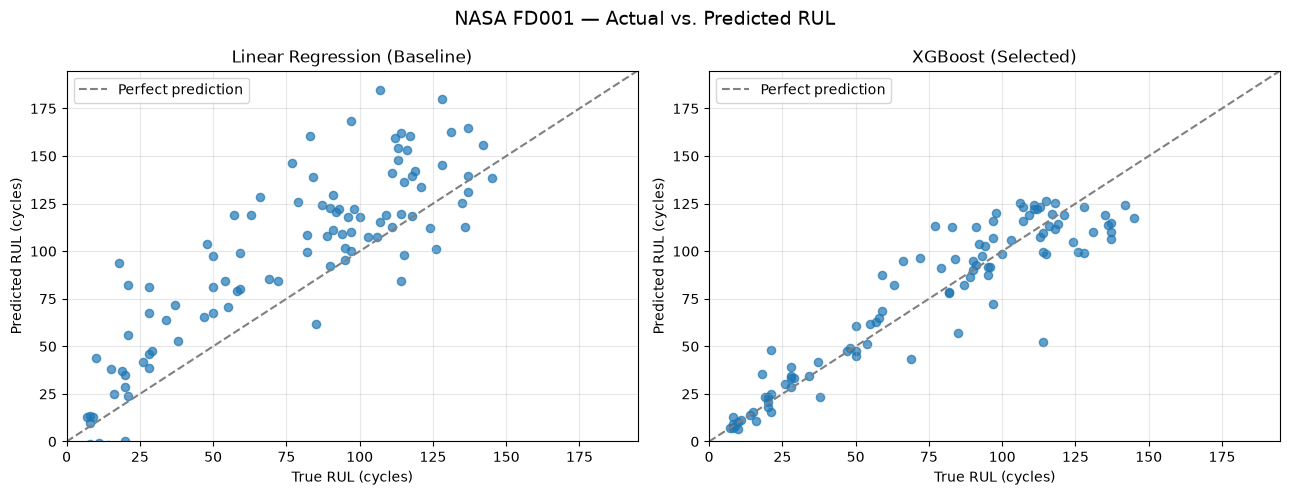

Figure saved: 05_evaluation/outputs/figures/actual_vs_predicted_rul.png


In [13]:

import matplotlib.pyplot as plt

# Create the figures directory.
FIG_DIR = OUTPUTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Official test labels and saved model predictions.
true_rul = prediction_results["true_rul"].to_numpy()

xgb_pred = prediction_results[
    "xgb_predicted_rul"
].to_numpy()

baseline_pred = prediction_results[
    "baseline_predicted_rul"
].to_numpy()

# Use the same axis limits for a fair comparison.
axis_max = max(
    true_rul.max(),
    xgb_pred.max(),
    baseline_pred.max()
) + 10

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Linear Regression (Baseline)", baseline_pred),
    ("XGBoost (Selected)", xgb_pred)
]

for ax, (model_name, predictions) in zip(axes, models):

    ax.scatter(
        true_rul,
        predictions,
        alpha=0.7,
        s=35
    )

    ax.plot(
        [0, axis_max],
        [0, axis_max],
        linestyle="--",
        color="gray",
        label="Perfect prediction"
    )

    ax.set_xlim(0, axis_max)
    ax.set_ylim(0, axis_max)

    ax.set_xlabel("True RUL (cycles)")
    ax.set_ylabel("Predicted RUL (cycles)")
    ax.set_title(model_name)

    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "NASA FD001 — Actual vs. Predicted RUL",
    fontsize=14
)

plt.tight_layout()

figure_path = FIG_DIR / "actual_vs_predicted_rul.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path.relative_to(REPO_DIR))



### Actual vs. Predicted RUL — Interpretation

The scatter plots compare the official NASA FD001 RUL labels with predictions from the Linear Regression baseline and the selected XGBoost model.

The XGBoost predictions are generally closer to the perfect prediction line, consistent with its lower overall MAE (10.974) and RMSE (15.258).

In contrast, the Linear Regression baseline shows greater dispersion and more frequent overestimation of remaining useful life.

For engines with high true RUL values, XGBoost predictions tend to remain near the 125-cycle target cap established during Modeling.

Although XGBoost demonstrates better overall prediction accuracy, individual overestimations remain important for maintenance safety.

Therefore, prediction accuracy must be considered together with late prediction risk before recommending operational deployment.


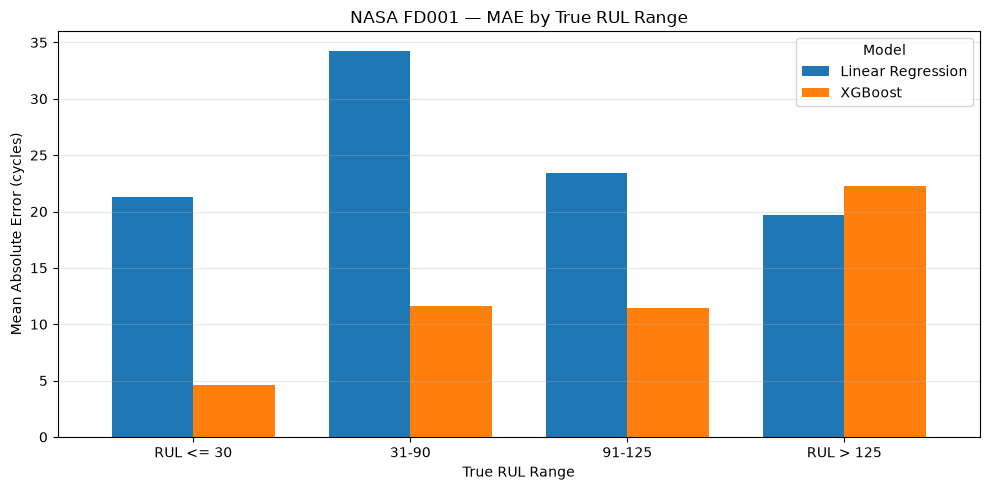

Figure saved: 05_evaluation/outputs/figures/mae_by_rul_range.png


In [14]:

# Compare MAE across true RUL ranges.

mae_plot_df = band_metrics_df.pivot(
    index="RUL Range",
    columns="Model",
    values="MAE"
).reindex(rul_labels)

ax = mae_plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("NASA FD001 — MAE by True RUL Range")
ax.set_xlabel("True RUL Range")
ax.set_ylabel("Mean Absolute Error (cycles)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model")

plt.tight_layout()

figure_path = FIG_DIR / "mae_by_rul_range.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path.relative_to(REPO_DIR))



### MAE by RUL Range — Interpretation

The bar chart compares the prediction errors of the Linear Regression baseline and the selected XGBoost model across four true RUL ranges.

XGBoost achieves lower MAE in three of the four RUL ranges.

For critical engines with true RUL <= 30, XGBoost achieves an MAE of 4.598 cycles, compared with 21.255 cycles for Linear Regression.

For engines with RUL between 31 and 125 cycles, XGBoost also provides substantially lower prediction errors.

However, for engines with true RUL > 125, Linear Regression achieves a lower MAE (19.664) than XGBoost (22.234).

The reduced accuracy of XGBoost in this range is consistent with the 125-cycle target cap used during Modeling.

Overall, the findings support XGBoost as the selected model for the project's maintenance decision horizon, while highlighting limitations for engines with longer remaining useful life.


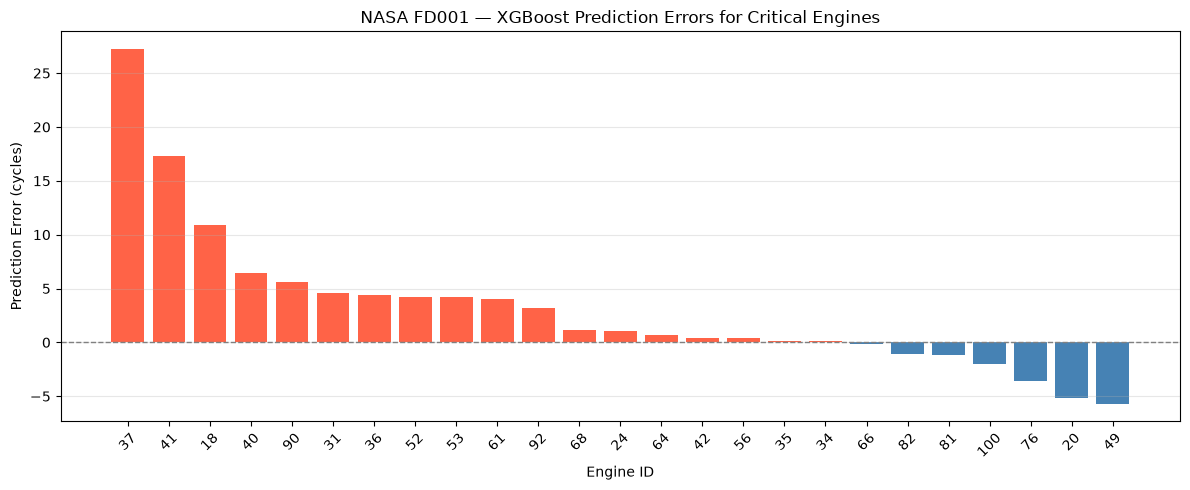

Figure saved: 05_evaluation/outputs/figures/critical_engine_prediction_errors.png


In [15]:

# Visualize XGBoost prediction errors for critical engines.

critical_plot = critical_df.sort_values("xgb_error", ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))

colors = [
    "tomato" if error > 0 else "steelblue"
    for error in critical_plot["xgb_error"]
]

ax.bar(
    critical_plot["unit"].astype(str),
    critical_plot["xgb_error"],
    color=colors
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "NASA FD001 — XGBoost Prediction Errors for Critical Engines"
)

ax.set_xlabel("Engine ID")
ax.set_ylabel("Prediction Error (cycles)")

ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

figure_path = FIG_DIR / "critical_engine_prediction_errors.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path.relative_to(REPO_DIR))



### Critical Engine Prediction Errors — Interpretation

The bar chart visualizes XGBoost prediction errors for the 25 official FD001 test engines with true RUL <= 30 cycles.

Positive values represent overestimation of remaining useful life, while negative values represent underestimation.

### Key Findings

- 18 of the 25 critical engines have positive prediction errors (72%).
- 7 engines have negative prediction errors (28%).
- Engine 37 has the largest overestimation (+27.233 cycles).
- Engine 41 has the second-largest overestimation (+17.312 cycles).
- Engine 18 has the third-largest overestimation (+10.928 cycles).

The results demonstrate that most late predictions are relatively small, but a few engines have substantially larger overestimations.

### Maintenance Implications

Overestimating RUL may lead to delayed inspections if maintenance decisions are based exclusively on model predictions.

The results highlight the importance of evaluating both prediction accuracy and the magnitude of individual errors.

The selected XGBoost model provides useful maintenance information, but its predictions should be combined with appropriate safety margins and human review.

These findings will be considered in the final Business Understanding evaluation and deployment readiness assessment.



## 7. Engine Inspection Priority Ranking

### Objective

Evaluate whether the selected XGBoost model can support maintenance inspection prioritization by ranking test engines according to their predicted Remaining Useful Life (RUL).

### Inspection Priority Strategy

In predictive maintenance, engines with lower predicted RUL values should generally receive higher inspection priority.

We rank all 100 official NASA FD001 test engines in ascending order of predicted RUL.

The engines with the lowest predicted RUL values are placed at the top of the inspection priority list.

### Ranking Evaluation

To assess whether the ranking is useful, we compare the model-based priority list with the actual remaining useful life of the test engines.

We examine:

- The 10 engines with the lowest predicted RUL.
- The 10 engines with the lowest true RUL.
- The overlap between these two groups.
- The actual RUL values of the engines selected for inspection.

This analysis evaluates whether XGBoost successfully identifies engines that are closest to failure.

### Evaluation Integrity

The inspection ranking is created using predicted RUL only.

True RUL labels are used afterward to evaluate ranking quality and are not used to determine the model-based inspection priority.

No model retraining, parameter tuning, or test-based model selection is performed.


In [16]:

# Rank test engines by predicted remaining useful life.

ranking_df = prediction_results.copy()

# Create the inspection priority list using predictions only.
ranking_df = ranking_df.sort_values(
    ["xgb_predicted_rul", "unit"],
    ascending=[True, True]
).reset_index(drop=True)

ranking_df["inspection_priority"] = (
    np.arange(1, len(ranking_df) + 1)
)

# Identify the 10 engines with the lowest predicted RUL.
top10_predicted = ranking_df.head(10).copy()

# Identify the 10 engines with the lowest actual RUL.
# Ground-truth labels are used only for evaluation.
top10_actual = (
    prediction_results
    .sort_values(["true_rul", "unit"])
    .head(10)
    .copy()
)

# Compare the two priority groups.
predicted_units = set(top10_predicted["unit"])
actual_units = set(top10_actual["unit"])

common_units = predicted_units.intersection(actual_units)

top10_overlap = len(common_units)

top10_recall = (
    top10_overlap / len(actual_units)
) * 100

# Verify ranking completeness.
assert len(ranking_df) == 100
assert ranking_df["unit"].nunique() == 100

print("Engine Inspection Priority Ranking")
print("-" * 55)

print("\nTop 10 engines by predicted RUL:")

print(
    top10_predicted[
        [
            "inspection_priority",
            "unit",
            "xgb_predicted_rul",
            "true_rul"
        ]
    ].round(3).to_string(index=False)
)

print("\nTop 10 engines by actual RUL:")

print(
    top10_actual[
        ["unit", "true_rul", "xgb_predicted_rul"]
    ].round(3).to_string(index=False)
)

print("\nRanking Evaluation Results")
print("-" * 55)

print("Top-10 overlap:", top10_overlap, "/ 10")

print(
    "Top-10 recall:",
    f"{top10_recall:.2f}%"
)

print(
    "Matching engine IDs:",
    sorted(common_units)
)

print("\nInspection priority ranking completed.")


Engine Inspection Priority Ranking
-------------------------------------------------------

Top 10 engines by predicted RUL:
 inspection_priority  unit  xgb_predicted_rul  true_rul
                   1    76              6.369        10
                   2    81              6.874         8
                   3    34              7.107         7
                   4    82              7.891         9
                   5    68              9.113         8
                   6    42             10.415        10
                   7    20             10.862        16
                   8    35             11.116        11
                   9    31             12.628         8
                  10    66             13.869        14

Top 10 engines by actual RUL:
 unit  true_rul  xgb_predicted_rul
   34         7              7.107
   31         8             12.628
   68         8              9.113
   81         8              6.874
   82         9              7.891
   42        10   


### Inspection Priority Ranking — Results and Interpretation

The selected XGBoost model was used to rank all 100 official FD001 test engines according to their predicted Remaining Useful Life (RUL).

Engines with lower predicted RUL values were assigned higher inspection priority.

### Ranking Performance

The model-based ranking was compared with the actual RUL ranking using the official NASA test labels.

The following results were obtained:

- Total test engines: 100.
- Top-10 overlap: 9 out of 10 engines.
- Top-10 recall: 90%.
- Matching engine IDs: 31, 34, 35, 42, 66, 68, 76, 81, and 82.

### Ranking Differences

Engine 20 was included in the predicted top-10 priority list, with a predicted RUL of 10.862 cycles and a true RUL of 16 cycles.

Engine 56 was included in the actual top-10 list but not in the predicted top-10 list. Its predicted RUL was 15.392 cycles, while its true RUL was 15 cycles.

The difference between these two engines' true RUL values was only one cycle.

### Business Interpretation

The 90% Top-10 recall indicates that the selected model successfully identifies most of the engines closest to failure.

This finding supports the project's objective of using RUL predictions to prioritize maintenance inspections.

However, a high ranking recall does not eliminate the risk of individual prediction errors.

Therefore, the inspection priority list should be used as decision support alongside safety margins and human review rather than as an autonomous maintenance scheduling system.


In [17]:

# Save the inspection priority ranking.

ranking_output = ranking_df[
    [
        "inspection_priority",
        "unit",
        "last_cycle",
        "xgb_predicted_rul",
        "true_rul"
    ]
].copy()

ranking_path = OUTPUTS_DIR / "inspection_priority_ranking.csv"

ranking_output.to_csv(
    ranking_path,
    index=False
)

# Verify the saved output.
saved_ranking = pd.read_csv(ranking_path)

assert len(saved_ranking) == 100
assert saved_ranking["inspection_priority"].tolist() == list(range(1, 101))
assert saved_ranking["unit"].is_unique

print("Ranking file saved:", ranking_path.relative_to(REPO_DIR))
print("Engines saved:", len(saved_ranking))
print("Inspection priority ranking verified.")


Ranking file saved: 05_evaluation/outputs/inspection_priority_ranking.csv
Engines saved: 100
Inspection priority ranking verified.



## 8. Isolation Forest Anomaly Evaluation

### Objective

Evaluate unusual sensor behavior in the official NASA FD001 test engines using the Isolation Forest detector developed during Stage 04 — Modeling.

### Consistency with Modeling

The saved anomaly detector is loaded directly from the Modeling artifacts without retraining or modifying its configuration.

The evaluation preserves the original feature selection, historical feature engineering, anomaly threshold, and sustained warning rule.

### Evaluation Strategy

We examine anomaly detection results across the observed test engine trajectories.

The analysis focuses on:

- Unusual sensor behavior identified by the saved detector.
- Anomaly flags for selected test engines.
- The relationship between anomaly warnings and engine deterioration.
- The usefulness and limitations of anomaly warnings for inspection planning.

### Evaluation Integrity

The official RUL labels are used only to evaluate the detector's behavior and are not used to modify its anomaly threshold or warning criteria.

The results will be compared with the Business Understanding criteria established in Stage 01.


In [18]:

# Inspect the saved anomaly detector configuration.

print("Isolation Forest Configuration")
print("-" * 50)

print("Pipeline type:",
      type(anomaly_detector["pipeline"]).__name__)

print("Feature count:",
      len(anomaly_detector["feature_columns"]))

print("Threshold:",
      anomaly_detector["threshold"])

print("Threshold rule:",
      anomaly_detector["threshold_rule"])

print("Sustained warning rule:",
      anomaly_detector["sustained_run"])

print("Anomaly score definition:",
      anomaly_detector["score"])

print("Healthy reference:",
      anomaly_detector["healthy_reference"])

print("\nPipeline steps:")
print(anomaly_detector["pipeline"].steps)

print("\nAnomaly configuration inspection completed.")


Isolation Forest Configuration
--------------------------------------------------
Pipeline type: Pipeline
Feature count: 14
Threshold: 0.5578926205103545
Threshold rule: 99% quantile of healthy-reference scores
Sustained warning rule: 5
Anomaly score definition: higher = more unusual (negated score_samples)
Healthy reference: first 30 cycles of each training engine

Pipeline steps:
[('standardscaler', StandardScaler()), ('isolationforest', IsolationForest(n_estimators=300, n_jobs=-1, random_state=42))]

Anomaly configuration inspection completed.



### Anomaly Detection on Official Test Trajectories

The saved Isolation Forest detector is applied to all observed cycles of the 100 official NASA FD001 test engines.

The detector uses the same 14 historical sensor features (10-cycle trailing means) and the saved preprocessing pipeline established during Stage 04 — Modeling.

Anomaly scores are calculated using the negative of the Isolation Forest `score_samples()` output, where higher scores indicate more unusual sensor behavior.

A cycle is flagged as anomalous when its score exceeds the saved threshold.

The threshold and model parameters remain unchanged during Evaluation.

We initially calculate cycle-level anomaly flags. Sustained warnings and their relationship with engine deterioration will be evaluated separately using the original five-cycle warning rule.


In [19]:

# Apply the saved Isolation Forest to official test trajectories.

anomaly_pipeline = anomaly_detector["pipeline"]
anomaly_threshold = anomaly_detector["threshold"]

# Use the original features and their saved order.
anomaly_input = test_history[
    anomaly_detector["feature_columns"]
].copy()

assert anomaly_input.shape == (13096, 14)
assert anomaly_input.notna().all().all()

# Higher scores indicate more unusual sensor behavior.
anomaly_scores = -anomaly_pipeline.score_samples(
    anomaly_input
)

# Apply the original threshold from Stage 04.
anomaly_flags = anomaly_scores > anomaly_threshold

# Store the results without modifying the original model.
anomaly_results = test_history[
    ["unit", "cycle"]
].copy()

anomaly_results["anomaly_score"] = anomaly_scores
anomaly_results["anomaly_flag"] = anomaly_flags

# Verification.
assert len(anomaly_results) == len(test_history)
assert np.isfinite(anomaly_scores).all()

print("Isolation Forest Test Results")
print("-" * 50)

print("Total observations:", len(anomaly_results))
print("Test engines:", anomaly_results["unit"].nunique())
print("Anomaly threshold:", anomaly_threshold)

print(
    "Flagged observations:",
    int(anomaly_results["anomaly_flag"].sum())
)

print(
    "Overall flag rate:",
    f"{anomaly_results['anomaly_flag'].mean() * 100:.2f}%"
)

print("\nFirst five anomaly results:")
print(anomaly_results.head().to_string(index=False))

print("\nCycle-level anomaly detection completed.")


Isolation Forest Test Results
--------------------------------------------------
Total observations: 13096
Test engines: 100
Anomaly threshold: 0.5578926205103545
Flagged observations: 1299
Overall flag rate: 9.92%

First five anomaly results:
 unit  cycle  anomaly_score  anomaly_flag
    1      1       0.514697         False
    1      2       0.456262         False
    1      3       0.449790         False
    1      4       0.437412         False
    1      5       0.441276         False

Cycle-level anomaly detection completed.



### Sustained Anomaly Warnings

A single unusual sensor observation does not necessarily indicate an immediate maintenance problem.

To reduce the influence of isolated anomalies, we apply the sustained warning rule established during Stage 04 — Modeling.

A sustained warning is triggered when an engine has at least five consecutive anomalous observations.

The rule is applied independently to each engine, using observations ordered by operating cycle.

The evaluation examines:

- The number of engines with sustained warnings.
- The first sustained warning cycle for each engine.
- The frequency of sustained warnings.
- The relationship between sustained warnings and the observed engine trajectories.

The previously trained detector, anomaly threshold, and five-cycle warning criterion remain unchanged.


In [20]:

# Apply the saved five-cycle sustained warning rule.

sustained_run = int(anomaly_detector["sustained_run"])

warning_df = anomaly_results.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True).copy()

# Count consecutive flagged observations within each engine.
warning_df["flag_group"] = (
    warning_df.groupby("unit")["anomaly_flag"]
    .transform(lambda s: s.ne(s.shift()).cumsum())
)

warning_df["consecutive_flags"] = (
    warning_df.groupby(["unit", "flag_group"]).cumcount() + 1
)

warning_df.loc[
    ~warning_df["anomaly_flag"], "consecutive_flags"
] = 0

# A warning begins on the fifth consecutive flagged cycle.
warning_df["sustained_warning"] = (
    warning_df["consecutive_flags"] >= sustained_run
)

# Verify consecutive warning logic.
assert not warning_df.loc[
    warning_df["sustained_warning"], "anomaly_flag"
].eq(False).any()

# Summarize sustained warnings by engine.
warning_summary = (
    warning_df.groupby("unit")
    .agg(
        observed_cycles=("cycle", "max"),
        flagged_cycles=("anomaly_flag", "sum"),
        warning_cycles=("sustained_warning", "sum")
    )
    .reset_index()
)

first_warnings = (
    warning_df[warning_df["sustained_warning"]]
    .groupby("unit")["cycle"]
    .min()
    .rename("first_warning_cycle")
)

warning_summary = warning_summary.merge(
    first_warnings,
    on="unit",
    how="left"
)

warning_summary["has_warning"] = (
    warning_summary["warning_cycles"] > 0
)

print("Sustained Anomaly Warning Results")
print("-" * 55)

print("Required consecutive cycles:", sustained_run)
print("Total test engines:", len(warning_summary))

print(
    "Engines with sustained warnings:",
    int(warning_summary["has_warning"].sum())
)

print(
    "Total sustained warning observations:",
    int(warning_df["sustained_warning"].sum())
)

print("\nFirst 10 engines with sustained warnings:")
print(
    warning_summary[
        warning_summary["has_warning"]
    ].head(10).to_string(index=False)
)

print("\nSustained warning analysis completed.")


Sustained Anomaly Warning Results
-------------------------------------------------------
Required consecutive cycles: 5
Total test engines: 100
Engines with sustained warnings: 38
Total sustained warning observations: 1036

First 10 engines with sustained warnings:
 unit  observed_cycles  flagged_cycles  warning_cycles  first_warning_cycle  has_warning
    3              126              11               7                120.0         True
   11               83              17               7                 61.0         True
   17              165               7               3                163.0         True
   20              184              35              31                154.0         True
   24              186              22              17                170.0         True
   31              196              48              43                154.0         True
   34              203              32              26                178.0         True
   35              19


### Selected Engine Anomaly Behavior

To investigate sustained anomaly warnings, we examine three official FD001 test engines: 31, 35, and 37.

These engines were selected for descriptive analysis because they show different warning patterns and have previously been examined in the RUL evaluation.

For each engine, we visualize:

- The anomaly score across observed operating cycles.
- The saved Isolation Forest anomaly threshold.
- Individual anomaly flags.
- Sustained warnings based on five consecutive anomalous observations.

These plots help identify when unusual behavior appears and whether it persists over time.

Anomaly warnings indicate unusual sensor patterns relative to the healthy training reference; they do not independently confirm engine failure.


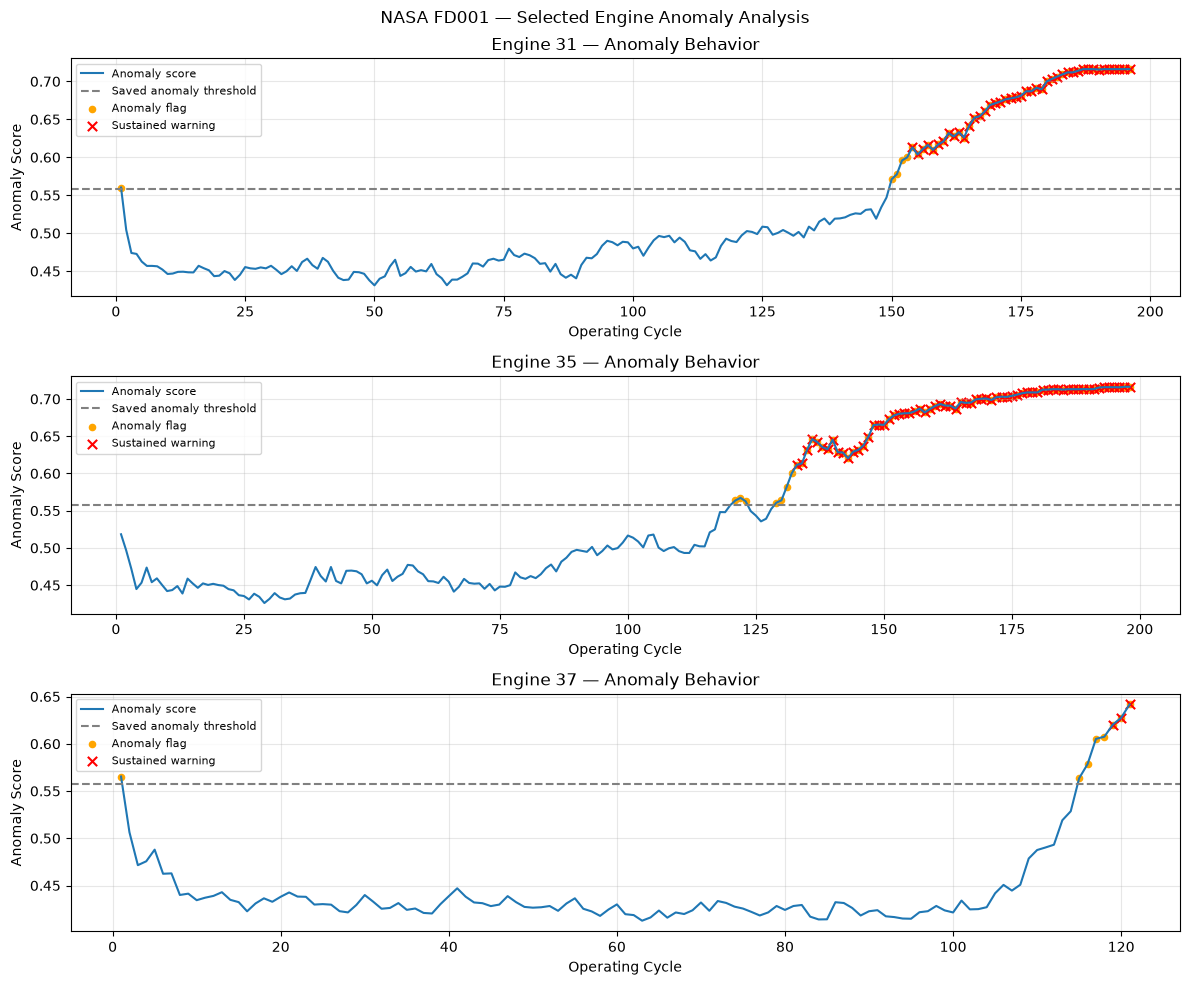

Figure saved: 05_evaluation/outputs/figures/selected_engine_anomaly_behavior.png
Selected engine anomaly visualization completed.


In [21]:

# Visualize anomaly behavior for selected test engines.

selected_units = [31, 35, 37]

fig, axes = plt.subplots(
    len(selected_units),
    1,
    figsize=(12, 10),
    sharex=False
)

for ax, unit in zip(axes, selected_units):

    engine = warning_df[
        warning_df["unit"] == unit
    ].sort_values("cycle")

    ax.plot(
        engine["cycle"],
        engine["anomaly_score"],
        label="Anomaly score"
    )

    ax.axhline(
        anomaly_threshold,
        color="gray",
        linestyle="--",
        label="Saved anomaly threshold"
    )

    flagged = engine[engine["anomaly_flag"]]

    ax.scatter(
        flagged["cycle"],
        flagged["anomaly_score"],
        color="orange",
        s=20,
        label="Anomaly flag"
    )

    sustained = engine[engine["sustained_warning"]]

    ax.scatter(
        sustained["cycle"],
        sustained["anomaly_score"],
        color="red",
        marker="x",
        s=45,
        label="Sustained warning"
    )

    ax.set_title(f"Engine {unit} — Anomaly Behavior")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Anomaly Score")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(
    "NASA FD001 — Selected Engine Anomaly Analysis"
)

plt.tight_layout()

figure_path = FIG_DIR / "selected_engine_anomaly_behavior.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path.relative_to(REPO_DIR))
print("Selected engine anomaly visualization completed.")



### Selected Engine Anomaly Behavior — Interpretation

The saved Isolation Forest detector was used to examine anomaly behavior in three official NASA FD001 test engines: 31, 35, and 37.

The original anomaly threshold and five-consecutive-cycle sustained warning rule were preserved.

### Engine 31

Engine 31 generated its first sustained warning at cycle 154.

The anomaly score increased substantially during the later observed cycles and remained above the saved threshold.

A total of 43 sustained warning observations were recorded.

This pattern indicates persistent unusual sensor behavior toward the end of the observed trajectory.

### Engine 35

Engine 35 generated its first sustained warning at cycle 133.

The anomaly score began increasing earlier, with a temporary threshold crossing followed by a more persistent increase.

A total of 66 sustained warning observations were recorded.

This suggests a prolonged period of unusual sensor behavior relative to the healthy reference.

### Engine 37

Engine 37 generated its first sustained warning at cycle 119.

The anomaly score remained relatively low for most observed cycles before rising sharply near the end of the trajectory.

Only 3 sustained warning observations were recorded.

This engine also showed the largest positive RUL prediction error among the critical test engines (+27.233 cycles).

### Maintenance Interpretation

The three engines demonstrate different anomaly warning patterns.

Engines 31 and 35 show sustained unusual behavior over longer periods, while Engine 37 shows a later and shorter warning period.

These findings indicate that anomaly detection may provide complementary information to RUL prediction for maintenance inspection planning.

However, anomaly scores do not directly identify the physical cause of unusual sensor behavior and should not be interpreted as confirmed failures.


In [22]:

# Compare sensor behavior between early and late observed cycles.

selected_units = [31, 35, 37]

sensor_columns = anomaly_detector["feature_columns"]

sensor_results = []

for unit in selected_units:

    engine = test_history[
        test_history["unit"] == unit
    ].sort_values("cycle")

    # Compare the first and last 20 observed cycles.
    early = engine.head(20)
    late = engine.tail(20)

    for sensor in sensor_columns:

        early_mean = early[sensor].mean()
        late_mean = late[sensor].mean()

        early_std = early[sensor].std()

        # Descriptive standardized change.
        if pd.notna(early_std) and early_std > 1e-9:
            standardized_change = (
                (late_mean - early_mean) / early_std
            )
        else:
            standardized_change = np.nan

        sensor_results.append({
            "unit": unit,
            "sensor": sensor,
            "early_mean": early_mean,
            "late_mean": late_mean,
            "mean_change": late_mean - early_mean,
            "standardized_change": standardized_change
        })

sensor_comparison_df = pd.DataFrame(sensor_results)

print("Early vs. Late Sensor Behavior")
print("-" * 60)

for unit in selected_units:

    subset = sensor_comparison_df[
        sensor_comparison_df["unit"] == unit
    ].copy()

    subset["absolute_change"] = (
        subset["standardized_change"].abs()
    )

    subset = subset.sort_values(
        "absolute_change",
        ascending=False,
        na_position="last"
    )

    print(f"\nEngine {unit} — Largest Sensor Changes")

    print(
        subset[
            [
                "sensor",
                "early_mean",
                "late_mean",
                "standardized_change"
            ]
        ].head(5).round(3).to_string(index=False)
    )

print("\nSensor behavior comparison completed.")


Early vs. Late Sensor Behavior
------------------------------------------------------------

Engine 31 — Largest Sensor Changes
          sensor  early_mean  late_mean  standardized_change
mean10_sensor_13    2388.010   2388.159               25.366
 mean10_sensor_8    2388.019   2388.165               24.237
mean10_sensor_11      47.321     47.902               20.287
mean10_sensor_15       8.413      8.488               18.853
 mean10_sensor_7     554.447    552.217              -17.810

Engine 35 — Largest Sensor Changes
          sensor  early_mean  late_mean  standardized_change
 mean10_sensor_9    9051.930   9073.424               29.266
mean10_sensor_11      47.516     47.954               23.641
mean10_sensor_14    8133.352   8148.696               14.450
 mean10_sensor_7     553.400    552.187              -13.624
mean10_sensor_20      38.835     38.587              -12.465

Engine 37 — Largest Sensor Changes
          sensor  early_mean  late_mean  standardized_change
mean10_


### Sensor Behavior Results and Interpretation

To investigate unusual sensor behavior, the first 20 and last 20 observed cycles of Engines 31, 35, and 37 were compared.

The analysis used the same sensor-related features established during Stage 04 — Modeling.

For each feature, the difference between the early and late means was standardized using the standard deviation of the early observations.

### Engine 31

Engine 31 showed substantial changes in several historical sensor features.

The largest standardized changes were:

- `mean10_sensor_13`: +25.366
- `mean10_sensor_8`: +24.237
- `mean10_sensor_11`: +20.287
- `mean10_sensor_7`: -17.810

The engine generated its first sustained anomaly warning at cycle 154 and recorded 43 sustained warning observations.

These sensor changes are consistent with the persistent increase in anomaly scores observed toward the end of its trajectory.

### Engine 35

Engine 35 showed notable changes in multiple sensor features.

The largest standardized changes were:

- `mean10_sensor_9`: +29.266
- `mean10_sensor_11`: +23.641
- `mean10_sensor_14`: +14.450
- `mean10_sensor_7`: -13.624

Its first sustained warning occurred at cycle 133, and 66 sustained warning observations were recorded.

This engine demonstrated the longest sustained warning pattern among the three selected examples.

### Engine 37

Engine 37 showed substantial changes in several historical sensor features.

The largest standardized changes were:

- `mean10_sensor_12`: -21.624
- `mean10_sensor_13`: +15.454
- `mean10_sensor_14`: -15.064
- `mean10_sensor_2`: +12.255

Its first sustained anomaly warning occurred at cycle 119, with only 3 sustained warning observations.

Engine 37 also had the largest late RUL prediction error among the critical test engines (+27.233 cycles).

This illustrates why anomaly detection and RUL prediction should be considered together during maintenance evaluation.

### Overall Interpretation

The three engines demonstrate different patterns of sensor change and sustained anomaly warnings.

The results support the usefulness of Isolation Forest as a complementary monitoring tool alongside XGBoost RUL predictions.

However, the standardized changes are descriptive measures based on early-period variability. Large values may partly reflect small early standard deviations.

They do not establish sensor-level causality, feature importance, or confirmed physical faults.

Therefore, anomaly flags should support further inspection and human review rather than independently determine maintenance actions.



## 9. Business Understanding Criteria and Deployment Readiness

### Objective

Evaluate whether the results obtained on the official NASA C-MAPSS FD001 test set support the predictive maintenance objectives established during Stage 01 — Business Understanding.

The evaluation considers RUL prediction accuracy, maintenance inspection prioritization, late prediction risks, anomaly detection, and practical limitations.

### 1. RUL Prediction Performance

The selected XGBoost model achieved:

- Test MAE: 10.974 cycles.
- Test RMSE: 15.258 cycles.
- Baseline MAE: 25.603 cycles.
- Baseline RMSE: 31.969 cycles.
- MAE reduction relative to baseline: 57.14%.

These results demonstrate that the selected model provides substantially better RUL predictions than the Linear Regression baseline.

### 2. Critical Engine Performance

For the 25 engines with true RUL <= 30:

- XGBoost MAE: 4.598 cycles.
- XGBoost RMSE: 7.533 cycles.
- Late predictions: 18 of 25 engines (72%).
- Average overestimation among late predictions: 5.338 cycles.
- Maximum overestimation: 27.233 cycles.

Although the model achieves low prediction error in the critical RUL range, several overestimations may be important for maintenance planning.

### 3. Inspection Prioritization

The selected XGBoost model was used to rank the 100 test engines according to predicted RUL.

The model achieved:

- Top-10 overlap: 9 out of 10 engines.
- Top-10 recall: 90%.

This result indicates that the model successfully identifies most of the engines closest to failure and supports inspection prioritization.

However, the ranking does not guarantee that every high-risk engine will be identified.

### 4. Anomaly Detection

The saved Isolation Forest detector was evaluated on 13,096 observations from 100 test engines.

The original detector configuration was preserved.

- Anomaly threshold: 0.5578926205103545.
- Flagged observations: 1,299.
- Overall anomaly flag rate: 9.92%.
- Sustained warning requirement: 5 consecutive anomalous observations.

Selected engine analyses demonstrated persistent or late-emerging unusual sensor behavior.

These findings suggest that anomaly detection can complement RUL predictions by providing additional information for inspection decisions.

### 5. Dataset and Methodological Limitations

The following limitations must be considered:

- The NASA C-MAPSS FD001 dataset contains simulated rather than real operational engine data.
- FD001 represents a single operating condition and a single fault mode.
- The evaluation includes 100 official test engines.
- The selected XGBoost model was trained using a 125-cycle RUL target cap, limiting its accuracy for longer remaining useful life values.
- Late RUL predictions may create maintenance risks if used without additional safeguards.
- Isolation Forest anomaly flags identify unusual sensor patterns but do not confirm physical faults.
- The evaluation does not establish real-world maintenance cost savings or operational safety.

### 6. Deployment Readiness Assessment

The selected XGBoost model demonstrates promising performance for predictive maintenance decision support.

Its RUL prediction accuracy and inspection prioritization results support a potential deployment demonstration.

However, the model is not considered ready for fully autonomous operational maintenance decisions.

A controlled demonstration may be appropriate, provided that predictions are interpreted alongside anomaly warnings, safety margins, and human review.

Additional validation using real operational data and broader operating conditions would be necessary before practical deployment.

### Overall Evaluation Conclusion

The Evaluation stage provides evidence that the selected XGBoost model can support the project's predictive maintenance objectives.

The model outperforms the baseline and successfully prioritizes most engines closest to failure.

Nevertheless, critical late prediction errors and dataset limitations prevent an unconditional recommendation for operational deployment.

The recommended next step is a controlled, simulation-based Deployment demonstration rather than direct integration into real aircraft maintenance operations.



### Verification Against Original Business Success Criteria

The original success criteria were defined in Stage 01 — Business Understanding before the final test evaluation.

The selected model was evaluated without retraining or changing the original model selection procedure.

| Original Success Criterion | Evaluation Evidence | Assessment |
|---|---|---|
| Achieve a lower test MAE than Linear Regression | XGBoost: 10.974; Linear Regression: 25.603 | Met |
| Report RMSE to examine large prediction errors | XGBoost: 15.258; Linear Regression: 31.969 | Met |
| Examine overestimation and underestimation of RUL | 18 overestimations and 7 underestimations among 25 critical engines | Met |
| Select the final model using validation MAE | The previously selected XGBoost model was reused without test-based model selection | Consistent with the established workflow |
| Evaluate whether Isolation Forest flags concentrate near failure on held-out validation engines | RUL <= 30: 99.35% (616/620); RUL > 30: 21.64% (754/3484) | Met — supported by Stage 04 validation results |

### Additional Maintenance Planning Evidence

The selected XGBoost model achieved a Top-10 Recall of 90% when inspection priorities were compared with the engines having the lowest actual RUL.

This is an additional evaluation result supporting the maintenance planning objective, rather than a predefined numerical success threshold.

### Overall Assessment

The selected XGBoost model satisfies the original test MAE improvement objective and provides lower RMSE than the Linear Regression baseline.

The evaluation also identifies important limitations, particularly RUL overestimation for some critical engines.

The Isolation Forest validation results support the original qualitative success criterion, with a substantially higher anomaly flag rate during the final 30 remaining cycles.

Therefore, the results support a controlled, simulation-based Deployment demonstration, but not autonomous operational maintenance decisions.



### Isolation Forest Success Criterion — Verification

Stage 01 — Business Understanding defined a qualitative anomaly detection success criterion: anomaly flags should be more frequent when engines have 30 or fewer remaining cycles than when they have more than 30 remaining cycles.

The Modeling-stage validation results were reviewed using the saved `anomaly_flag_rates.csv` artifact.

| Validation RUL Group | Observations | Flagged Observations | Flag Rate |
|---|---:|---:|---:|
| RUL <= 30 | 620 | 616 | 99.35% |
| RUL > 30 | 3,484 | 754 | 21.64% |

### Assessment

The anomaly flag rate is substantially higher for observations with RUL <= 30.

This supports the qualitative success criterion defined during Business Understanding.

The detector configuration and anomaly threshold were established during Modeling and were not modified using the official test dataset.

These rates describe the relationship between anomaly flags and remaining useful life in the validation data.

They are not anomaly precision or recall metrics because independently labeled anomalous observations are unavailable.

### Final Business Criteria Assessment

The Evaluation results support the original project objectives:

- The selected XGBoost model achieved a lower official test MAE than the Linear Regression baseline.
- MAE and RMSE were reported for both models.
- Overestimation and underestimation risks were examined.
- Inspection prioritization was evaluated using Top-10 Recall.
- The Modeling-stage Isolation Forest validation results support the original qualitative anomaly detection criterion.

Despite these positive findings, critical late prediction errors and the limitations of simulated data remain important.

The recommended next step is a controlled, simulation-based Deployment demonstration with human oversight.



## 10. Export Evaluation Results

The final evaluation results are exported as CSV files to ensure reproducibility, transparency, and traceability.

The exported files contain:

- RUL predictions for the official FD001 test engines.
- MAE and RMSE results for the baseline and selected models.
- Prediction errors across RUL ranges.
- Critical engine prediction errors.
- Engine inspection priority rankings.
- Cycle-level anomaly scores and flags.
- Sustained anomaly warnings.
- Selected engine sensor behavior comparisons.

All outputs are generated using the previously saved models and the official test dataset.

No model retraining, parameter tuning, or test-based model selection is performed during export.


In [23]:

# Export the completed Stage 05 evaluation results.

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

evaluation_exports = {
    "test_rul_predictions.csv": prediction_results,
    "model_test_metrics.csv": metrics_df,
    "rul_band_metrics.csv": band_metrics_df,
    "critical_engine_predictions.csv": critical_df,
    "inspection_priority_ranking.csv": ranking_df,
    "test_anomaly_scores.csv": anomaly_results,
    "sustained_anomaly_warnings.csv": warning_df.drop(
        columns=["flag_group"],
        errors="ignore"
    ),
    "engine_warning_summary.csv": warning_summary,
    "selected_engine_sensor_comparison.csv": sensor_comparison_df
}

print("Stage 05 — Evaluation CSV Exports")
print("-" * 65)

for filename, dataframe in evaluation_exports.items():

    assert isinstance(dataframe, pd.DataFrame), (
        f"{filename}: expected a pandas DataFrame"
    )

    assert not dataframe.empty, (
        f"{filename}: DataFrame is empty"
    )

    output_path = OUTPUTS_DIR / filename

    dataframe.to_csv(output_path, index=False)

    # Verify that the exported file can be read.
    verified_df = pd.read_csv(output_path)

    assert len(verified_df) == len(dataframe), (
        f"{filename}: row count mismatch"
    )

    print(
        f"{filename}: "
        f"{len(dataframe)} rows — SAVED"
    )

print("-" * 65)
print("All evaluation CSV exports completed successfully.")


Stage 05 — Evaluation CSV Exports
-----------------------------------------------------------------
test_rul_predictions.csv: 100 rows — SAVED
model_test_metrics.csv: 2 rows — SAVED
rul_band_metrics.csv: 8 rows — SAVED
critical_engine_predictions.csv: 25 rows — SAVED
inspection_priority_ranking.csv: 100 rows — SAVED
test_anomaly_scores.csv: 13096 rows — SAVED
sustained_anomaly_warnings.csv: 13096 rows — SAVED
engine_warning_summary.csv: 100 rows — SAVED
selected_engine_sensor_comparison.csv: 42 rows — SAVED
-----------------------------------------------------------------
All evaluation CSV exports completed successfully.
